# orbit-agent: know the data first

Before any model: what is in the photos, how clean are the labels, and can we trust the test?
We did this analysis late (22 Oct), but it belongs first: every later experiment
([02_experiments.ipynb](02_experiments.ipynb)) rests on it, and experiment 12 retrains the model because of it.

**Three data sets:**

| Data set | What | Classes | Used for |
|---|---|---|---|
| **EuroSAT** | real Sentinel-2 photos, 64 x 64 px, Europe | 10 land types, equal sizes | first tests; the head on a real satellite camera |
| **AID** | sharp aerial photos (Google Earth), 600 x 600 px | 30 scene types | the data set NASA's NAVI-Orbital used; labeller comparisons |
| **Real Sentinel-2A replay** | what Sentinel-2A *really* photographed at each 30 s of its real orbit | 8 classes, very uneven | **the main results**: the audit, the self-check, retraining |

Needs the downloaded photos (`python -m src.data.eurosat`, `src.data.aid`, `src.data.s2_real`, `src.data.s2_bands`).
Takes about 2 minutes.

In [1]:
# Setup
import os, sys, json, hashlib
from collections import Counter
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir("..")
sys.path.insert(0, ".")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as Show, display
from PIL import Image

from src.data import aid, eurosat, s2_bands, s2_real
from src.paths import result

pd.options.display.float_format = lambda v: f"{v:g}"
plt.rcParams.update({"figure.facecolor": "white", "font.size": 10})


def grid(paths, titles, cols=8, size=1.6, suptitle=None):
    """Show photos in a grid with a small title under each."""
    rows = (len(paths) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * (size + 0.35)))
    for ax in np.atleast_1d(axes).ravel():
        ax.axis("off")
    for ax, p, t in zip(np.atleast_1d(axes).ravel(), paths, titles):
        ax.axis("on")  # a thin grey frame, so all-white photos (cloud, snow) stay visible
        ax.set_xticks([]); ax.set_yticks([])
        for side in ax.spines.values():
            side.set_color("#bbbbbb")
        ax.imshow(Image.open(p).convert("RGB"))
        ax.set_title(t, fontsize=8)
    if suptitle:
        fig.suptitle(suptitle, x=0.01, ha="left", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()


def figure(name, width=850):
    display(Show(filename=f"docs/figures/{name}", width=width))

## 1. EuroSAT: real Sentinel-2 photos (64 x 64 px)

In [2]:
root = eurosat.dataset_dir()
paths = {c: eurosat.photos_in(root / c) for c in eurosat.CLASSES}
pd.DataFrame({"photos": {c: len(v) for c, v in paths.items()}}).T

,AnnualCrop,Forest,HerbaceousVegetation,Highway,Industrial,Pasture,PermanentCrop,Residential,River,SeaLake
photos,3000,3000,3000,2500,2500,2000,2500,3000,2500,3000


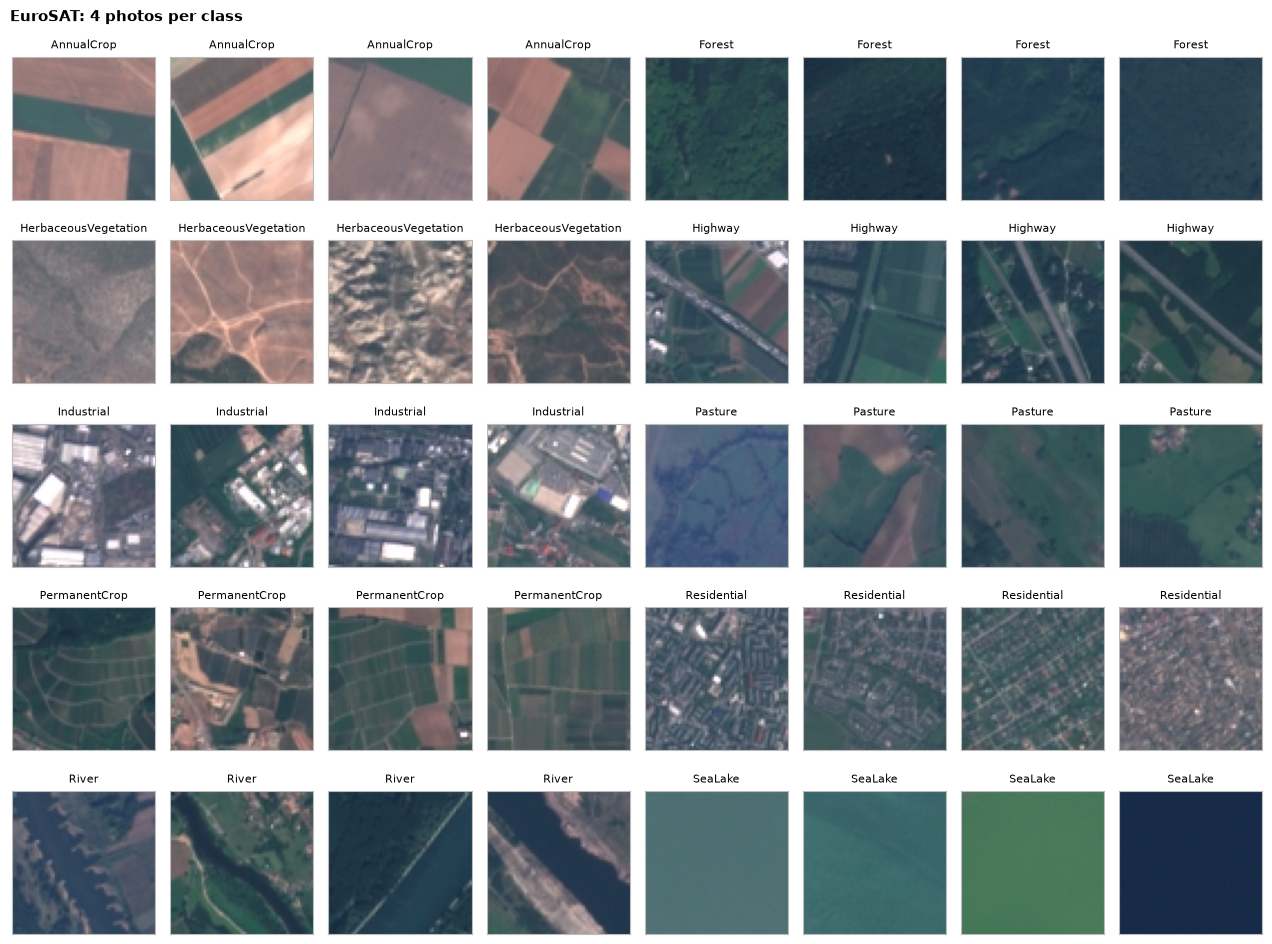

In [3]:
rng = np.random.default_rng(0)
pick = [(c, p) for c in eurosat.CLASSES for p in rng.choice(paths[c], 4, replace=False)]
grid([p for _, p in pick], [c for c, _ in pick], cols=8, suptitle="EuroSAT: 4 photos per class")

In [4]:
# Quality: same photo twice? one size? broken (very dark) photos?
hashes, sizes, dark = Counter(), Counter(), 0
for c, files in paths.items():
    for p in files:
        a = np.asarray(Image.open(p).convert("RGB"))
        hashes[hashlib.md5(a.tobytes()).hexdigest()] += 1
        sizes[a.shape[:2]] += 1
        dark += a.mean() < 15
pd.DataFrame([{"photos": sum(hashes.values()), "exact duplicates": sum(n - 1 for n in hashes.values() if n > 1),
               "photo sizes": dict(sizes), "very dark photos": int(dark)}])

,photos,exact duplicates,photo sizes,very dark photos
0,27000,0,"{(64, 64): 27000}",0


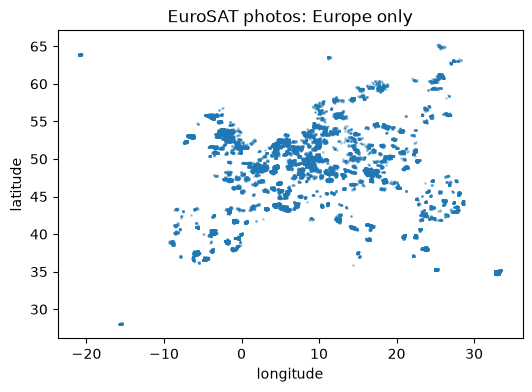

In [5]:
# Where: real coordinates of every photo (from the GeoTIFF version, src/data/eurosat_geo.py)
coords = pd.read_csv("data/processed/eurosat_coords.csv")
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(coords.lon, coords.lat, s=1, alpha=0.3)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.set_title("EuroSAT photos: Europe only")
plt.show()

In [6]:
# Are neighbouring tiles leaking from training into test? Test split by location (10 km and 50 km blocks)
split = pd.read_csv(result("spatial_split_eurosat_20261022_1328.csv"))
split.groupby("block_km")[["accuracy", "final_with_twin"]].mean().assign(random_split_accuracy=0.927)

,accuracy,final_with_twin,random_split_accuracy
block_km,,,
10,0.934333,695,0.927
50,0.925333,672,0.927


**EuroSAT is clean:** 27,000 photos, no duplicates, one size, nothing broken, all from Europe.
Keeping training and test photos 10-50 km apart gives the same accuracy as a random split (93.4% / 92.5% vs
92.7%): **no neighbouring-tile leak**. The limits are known: 64 px is small, and it is Europe only.

## 2. AID: sharp aerial photos (600 x 600 px)

Full data set: 10,000 photos, 220 (BaseballField) to 420 (Pond) per class


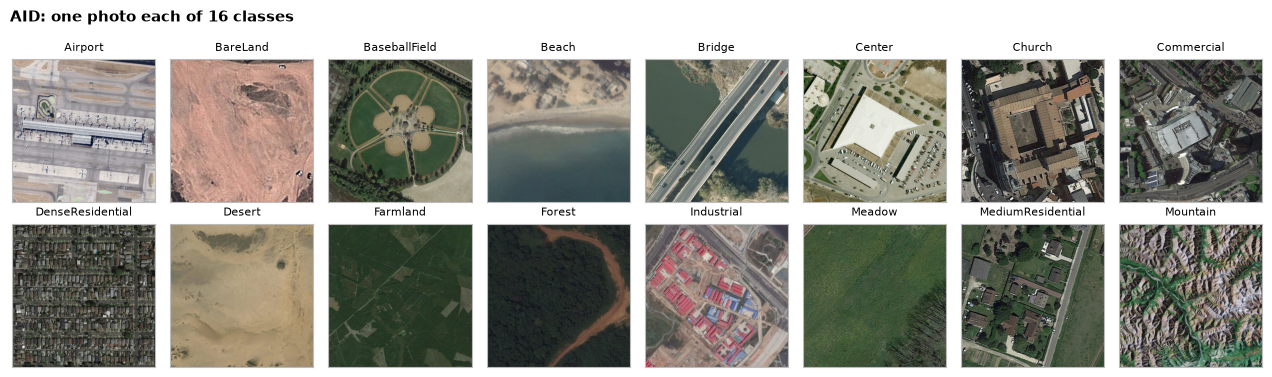

In [7]:
files = json.loads(aid.FILE_LIST.read_text())
full = pd.Series({c: len(v) for c, v in files.items()}).sort_values()
print(f"Full data set: {full.sum():,} photos, {full.min()} ({full.idxmin()}) to {full.max()} ({full.idxmax()}) per class")
here = {c: sorted((aid.AID_DIR / c).glob("*.jpg")) for c in aid.LABELS}
grid([here[c][0] for c in list(aid.LABELS)[:16]], list(aid.LABELS)[:16], cols=8, suptitle="AID: one photo each of 16 classes")

In [8]:
kb = pd.Series({c: np.mean([p.stat().st_size for p in v]) / 1000 for c, v in here.items()}).sort_values()
sizes = Counter(Image.open(p).size for v in here.values() for p in v)
print(f"Downloaded: {sum(len(v) for v in here.values()):,} photos, sizes {dict(sizes)}")
print(f"JPEG size by class: {kb.index[0]} {kb.iloc[0]:.0f} KB ... {kb.index[-1]} {kb.iloc[-1]:.0f} KB")

Downloaded: 2,400 photos, sizes {(600, 600): 2400}
JPEG size by class: Port 139 KB ... SparseResidential 720 KB


**AID is clean** (no duplicates, one size). Its classes differ in size in the full set (220-420), but every
test and training set we use takes the same number per class. JPEG sizes differ 5x by class (simple scenes
compress well), which is why the replay gives every photo the same size: otherwise an agent could look
better just by picking small files.

## 3. The real Sentinel-2A replay: the main data

**How it was made** (`src/data/s2_real.py`): Sentinel-2A's real orbit gives a photo "slot" every 30 s in
daylight. For each slot we ask the free Sentinel-2 catalogue (Element 84, AWS) for the image Sentinel-2A
really took there within 5 minutes, and cut out a 224 x 224 px chip (2.24 km). Open ocean has no images.

**Labels** come from two maps, not people: the image's own cloud map (mostly cloud -> Cloud, mostly snow ->
SnowIce), else the most common land type in ESA WorldCover 2021.

**Days:** 6-11 Oct train, 12 Oct tune, 13-19 Oct test. Later (experiment 12) we added 15 Sep - 5 Oct for
training only, so the test never changes.

In [9]:
main = pd.DataFrame(s2_real.load_chips(s2_real.MAIN_DAYS))
main["part"] = np.where(main.day.isin(s2_real.TEST_DAYS), "test (13-19 Oct)", "training + tuning (6-12 Oct)")
slots = pd.read_csv(s2_real.SLOTS_CSV)
slots = slots[slots.day.isin(s2_real.MAIN_DAYS)]
print(f"{len(slots):,} daylight slots on 6-19 Oct -> {len(main):,} real photos ({len(main) / len(slots):.0%}; the rest is open ocean)")
print(f"Real image time vs simulated slot: {main.gap_s.astype(float).max():.0f} s at most")
mix = main.groupby(["label", "part"]).size().unstack("part").fillna(0).astype(int)
mix["share"] = (mix.sum(axis=1) / len(main) * 100).round(1)
mix.sort_values("share", ascending=False)

20,176 daylight slots on 6-19 Oct -> 3,527 real photos (17%; the rest is open ocean)
Real image time vs simulated slot: 9 s at most


part,test (13-19 Oct),training + tuning (6-12 Oct),share
label,,,
Cloud,772,843,45.8
Water,310,283,16.8
ShrubGrass,239,200,12.4
Trees,177,208,10.9
Bare,139,135,7.8
Cropland,83,91,4.9
SnowIce,28,15,1.2
BuiltUp,1,3,0.1


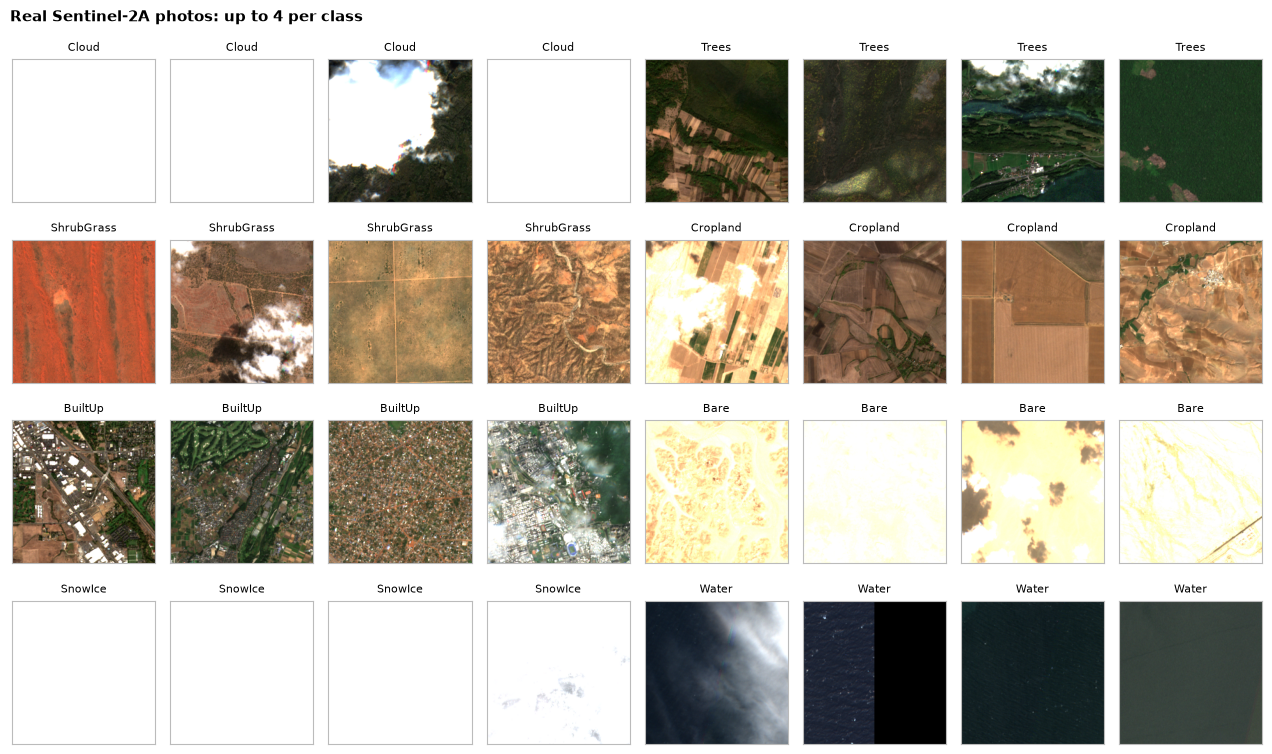

In [10]:
rng = np.random.default_rng(1)
pick = [(c, r) for c in s2_real.CLASSES for _, r in main[main.label == c].sample(min(4, (main.label == c).sum()), random_state=1).iterrows()]
grid([s2_real.OUT_DIR / r.day / r["name"] for _, r in pick], [c for c, _ in pick], cols=8,
     suptitle="Real Sentinel-2A photos: up to 4 per class")

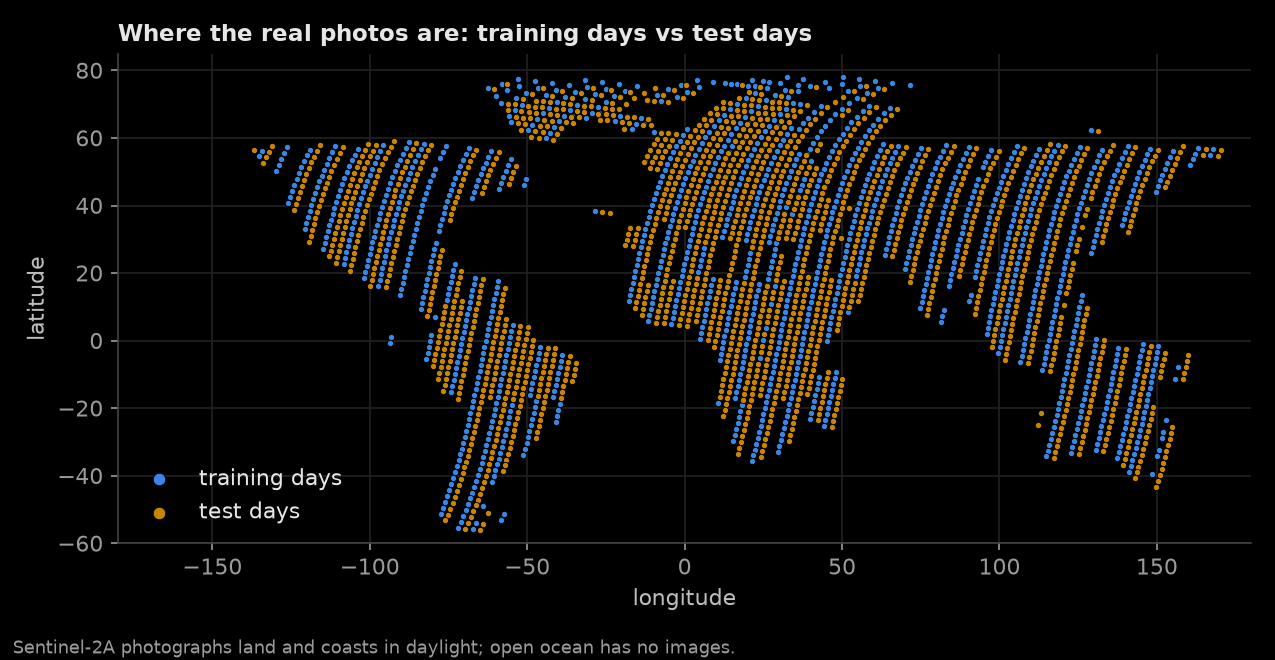

In [11]:
figure("eda_map.png")

**Very uneven:** Cloud 46%, Water 17%, and only 43 snow and 4 built-up photos in two weeks. Training and test
days have almost the same mix (5% difference), and places don't repeat (only 93 of 1,749 test photos are
within 10 km of a training photo).

### 3.1 Messy photos

Five data problems, with rules fixed before looking at any model result (`src/eval/eda.py`):

In [12]:
chips = pd.read_csv(result("eda_real_chips.csv"))
flags = {"partly_cloudy": "land label, but 20-50% cloud", "border_cloud": "cloud label, but only 50-70% cloud",
         "mixed": "land label covers under half the photo", "nodata": "more than 5% no-data (black strips)",
         "blown_out": "land label, but over half pure white"}
pd.DataFrame([{"problem": text, "photos": int(chips[f].sum()), "share": f"{chips[f].mean():.1%}",
               "mostly": ", ".join(chips[chips[f]].label.value_counts().index[:3])} for f, text in flags.items()]
             + [{"problem": "clean (none of these)", "photos": int(chips.clean.sum()), "share": f"{chips.clean.mean():.1%}", "mostly": ""}])

,problem,photos,share,mostly
0,"land label, but 20-50% cloud",230,6.5%,"Water, Trees, ShrubGrass"
1,"cloud label, but only 50-70% cloud",128,3.6%,Cloud
2,land label covers under half the photo,75,2.1%,"ShrubGrass, Cropland, Trees"
3,more than 5% no-data (black strips),57,1.6%,"Cloud, Water, Trees"
4,"land label, but over half pure white",18,0.5%,"Bare, Trees, ShrubGrass"
5,clean (none of these),3043,86.3%,


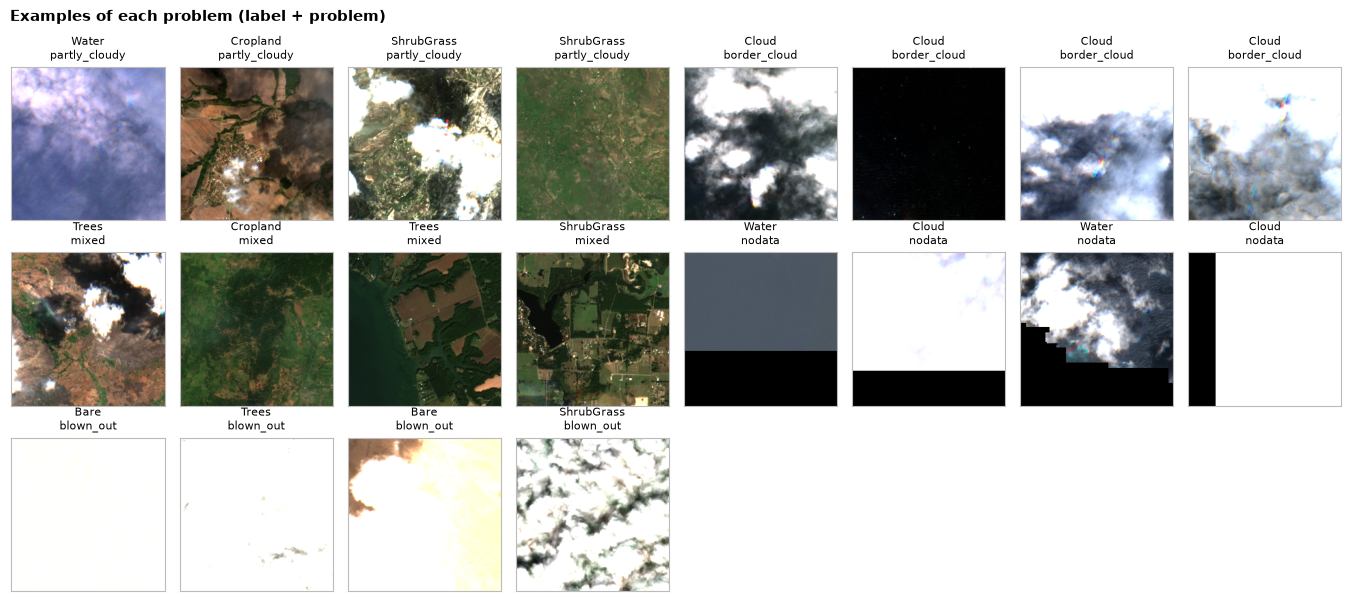

In [13]:
examples = []
for f in flags:
    for _, r in chips[chips[f]].sample(4, random_state=0).iterrows():
        examples.append((s2_real.OUT_DIR / r.day / r["name"], f"{r.label}\n{f}"))
grid([p for p, _ in examples], [t for _, t in examples], cols=8, size=1.7, suptitle="Examples of each problem (label + problem)")

### 3.2 Snow and cloud: the colour photos can't tell them apart

Photos more than half pure white, by class:
label
Bare             12 of 274
BuiltUp             0 of 4
Cloud         1131 of 1615
Cropland          1 of 174
ShrubGrass        2 of 439
SnowIce           42 of 43
Trees             3 of 385
Water             0 of 593


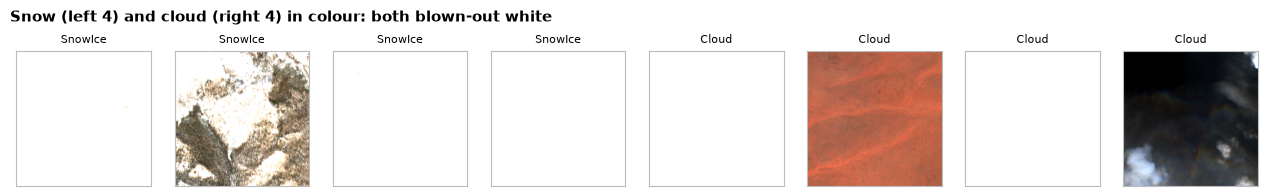

In [14]:
white = chips.groupby("label")["white"].apply(lambda w: f"{(w > 0.5).sum()} of {len(w)}")
print("Photos more than half pure white, by class:"); print(white.to_string())
snow = main[main.label == "SnowIce"].sample(4, random_state=0)
cloud = main[main.label == "Cloud"].sample(4, random_state=0)
both = list(snow.itertuples()) + list(cloud.itertuples())
grid([s2_real.OUT_DIR / r.day / r.name for r in both], ["SnowIce"] * 4 + ["Cloud"] * 4, cols=8,
     suptitle="Snow (left 4) and cloud (right 4) in colour: both blown-out white")

The colour product saturates on bright surfaces, so snow and cloud both become plain white. In **short-wave
infrared** (Sentinel-2 band 11) snow is dark. The standard snow index NDSI = (green - SWIR) / (green + SWIR)
is high for snow (`src/data/s2_bands.py`):

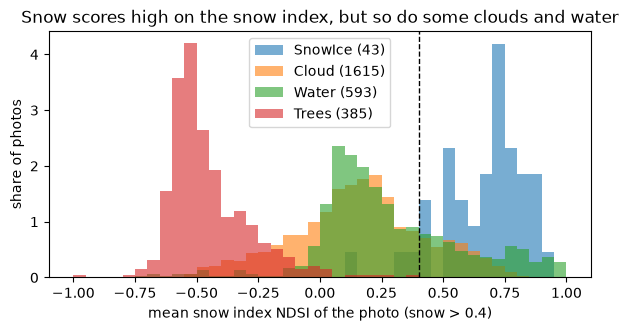

,photos,mean NDSI,photos with NDSI > 0.4
SnowIce,43,0.66,93%
Cloud,1615,0.16,19%
Water,593,0.28,29%
Trees,385,-0.45,0%


In [15]:
feats = {c: np.stack([s2_bands.features(r) for r in s2_real.load_chips(s2_real.MAIN_DAYS) if r["label"] == c])
         for c in ("SnowIce", "Cloud", "Water", "Trees")}
fig, ax = plt.subplots(figsize=(7, 3.2))
for c, f in feats.items():
    ax.hist(f[:, 0], bins=np.linspace(-1, 1, 41), alpha=0.6, density=True, label=f"{c} ({len(f)})")
ax.axvline(0.4, color="black", lw=1, ls="--")
ax.set_xlabel("mean snow index NDSI of the photo (snow > 0.4)"); ax.set_ylabel("share of photos")
ax.legend(); ax.set_title("Snow scores high on the snow index, but so do some clouds and water"); plt.show()
pd.DataFrame({c: {"photos": len(f), "mean NDSI": f[:, 0].mean().round(2), "photos with NDSI > 0.4": f"{(f[:, 0] > 0.4).mean():.0%}"}
              for c, f in feats.items()}).T

**Infrared helps, but it is not a clean switch.** 93% of snow photos score above 0.4, but so do 19% of cloud
photos and 29% of water photos. The cloud photos that look snow-like are thick **ice clouds** (pure white, many
in the tropics, where there is no snow): ice crystals absorb short-wave infrared just like snow. Water absorbs it
too. Experiment 12 tests how much these numbers help the model.

### 3.3 Do the labels agree with similar photos?

For every photo, the share of its 10 most similar photos (in the image model's space) with the same label.
Low agreement = a suspicious label, or a class that blends into others.

In [16]:
agree = chips.groupby("label")["neighbour_agreement"].mean().sort_values(ascending=False)
eye = pd.read_csv(result("label_check_real.csv")).merge(chips[["name", "neighbour_agreement"]], on="name")
display(pd.DataFrame({"neighbour agreement": agree.map(lambda v: f"{v:.0%}")}).T)
eye.groupby("by_eye")["neighbour_agreement"].agg(["count", "mean"]).rename(columns={"mean": "neighbour agreement"})

label,Cloud,Water,Bare,Trees,ShrubGrass,Cropland,SnowIce,BuiltUp
neighbour agreement,86%,84%,69%,54%,50%,47%,18%,5%


,count,neighbour agreement
by_eye,,
agree,119,0.707563
disagree,4,0.05
unsure,27,0.281481


The eye check (150 photos looked at one by one, `src/eval/label_check.py`) confirms the measure: photos whose
label looked right score 71%, "can't tell" 28%, "label wrong" 5%. Trees, ShrubGrass and Cropland agree only
about half the time: at 10 m these land types blend into each other. 395 photos (11%) are worth a person's look
(`results/00_data/eda_real_chips.csv`, column `neighbour_agreement`).

### 3.4 Where are the model's mistakes?

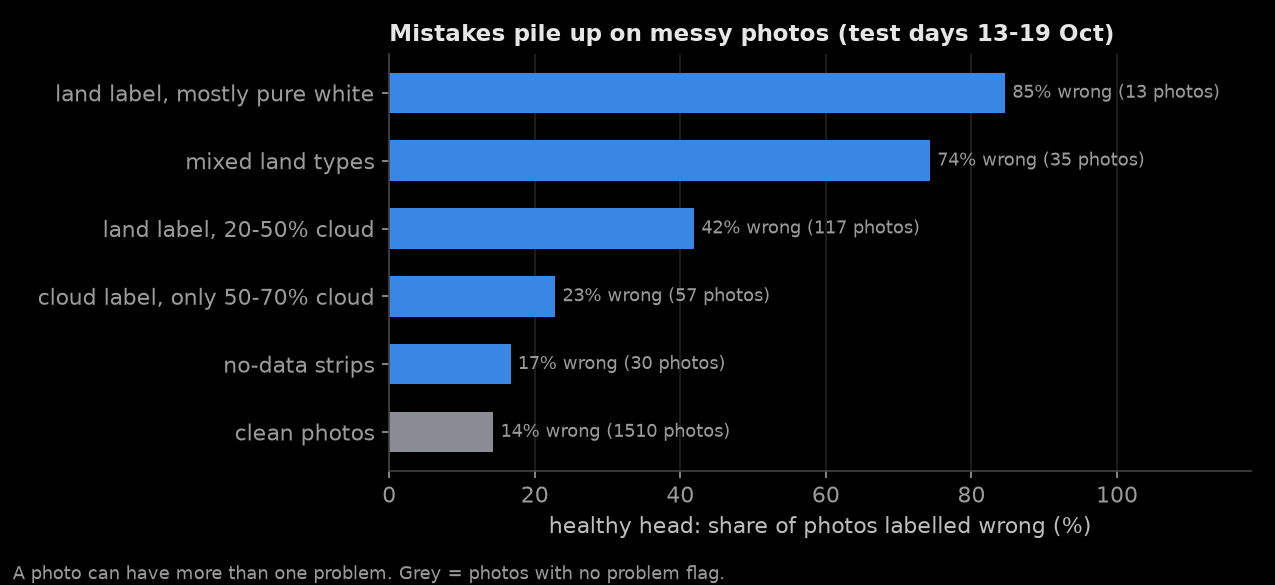

In [17]:
figure("eda_quality.png")

The 30 KB head (trained 6-11 Oct) is wrong on 14% of clean test photos, but on 42-85% of messy ones. Messy
photos are 14% of the test days and carry 30% of the mistakes. So **part** of the error is the data; most of it
is the model mixing up Trees, ShrubGrass and Cropland, and calling all snow "Cloud".

### 3.5 How much do the numbers move?

In [18]:
sens = pd.read_csv(result("eda_sensitivity_real_20261022_1417.csv"))
sens[["variant", "train_photos", "test_photos", "accuracy", "accuracy_low", "accuracy_high", "balanced_accuracy", "macro_f1"]]

,variant,train_photos,test_photos,accuracy,accuracy_low,accuracy_high,balanced_accuracy,macro_f1
0,"as used: train 6-11, tune 12, test 13-19",1525,1749,0.8228,0.805,0.8399,0.6697,0.6637
1,"same head, clean test photos only",1525,1510,0.857,0.8391,0.8742,0.708,0.6925
2,clean training + clean test photos,1318,1510,0.851,0.8331,0.8682,0.6923,0.6855
3,"reversed: train 13-18, tune 19, test 6-12",1489,1778,0.8183,0.7987,0.8358,0.6565,0.6625
4,"interleaved: train even days, test odd days",1456,1793,0.8126,0.7942,0.8299,0.6547,0.6517
5,"interleaved: train odd days, test even days",1533,1734,0.8212,0.8028,0.8397,0.663,0.668


In [19]:
clean = pd.read_csv(result("eda_audit_clean_20261022_1417.csv"))
t = clean[clean.rate_mbps == 0.05].assign(cell=lambda d: d.rmse_pts.round(1).astype(str) + " / " + (100 * d.bar_held).round().astype(int).astype(str) + "%")
t.pivot_table(index=["scenario", "method"], columns="photos", values="cell", aggfunc="first")

photos                                      all photos clean photos
scenario                 method                                    
bit flips                audit, self-check   5.5 / 97%    5.0 / 98%
                         labels only        10.6 / 27%    5.8 / 58%
                         raw random          5.9 / 96%    5.8 / 96%
                         triage (v4)        10.8 / 27%    6.5 / 52%
healthy head             audit, self-check   3.6 / 98%    3.0 / 99%
                         labels only         1.9 / 80%    1.8 / 84%
                         raw random          5.9 / 96%    5.8 / 96%
                         triage (v4)         1.5 / 84%    1.2 / 88%
new place (EuroSAT head) audit, self-check   5.3 / 98%    5.7 / 97%
                         labels only         19.5 / 9%    20.4 / 8%
                         raw random          5.9 / 96%    5.8 / 96%
                         triage (v4)        16.6 / 20%   17.0 / 23%

- Other day splits move accuracy by about **1 point** (81.3-82.3%). The results don't depend on lucky days.
- Cleaning the test photos adds about **3.5 points**. Cleaning the training photos adds nothing.
- **The main result (the audit) is the same on clean photos:** with a broken model, labels-only and triage
  still fail silently, and the self-checking audit's error bars still hold 94-99%.

## 4. Three more weeks for training (15 Sep - 5 Oct)

Only 15 snow and 3 built-up photos were in the training days. We downloaded three more weeks of what
Sentinel-2A photographed, for **training only** (the test days stay 13-19 Oct).

In [20]:
extra = pd.DataFrame(s2_real.load_chips(s2_real.EXTRA_DAYS))
both = pd.DataFrame({"6-11 Oct (training)": main[main.day.isin(s2_real.TRAIN_DAYS)].label.value_counts(),
                     "15 Sep - 5 Oct (new, training)": extra.label.value_counts(),
                     "13-19 Oct (test)": main[main.day.isin(s2_real.TEST_DAYS)].label.value_counts()}).fillna(0).astype(int)
print(f"{len(extra):,} new photos over {extra.day.nunique()} days; real image time vs slot at most {extra.gap_s.astype(float).max():.0f} s")
both.loc[s2_real.CLASSES]

5,633 new photos over 21 days; real image time vs slot at most 15 s


,6-11 Oct (training),"15 Sep - 5 Oct (new, training)",13-19 Oct (test)
label,,,
Cloud,725,2686,772
Trees,174,611,177
ShrubGrass,166,667,239
Cropland,77,247,83
BuiltUp,3,6,1
Bare,112,435,139
SnowIce,15,105,28
Water,253,876,310


## 5. What the data told us, and what we changed

| Finding | What we did about it |
|---|---|
| EuroSAT and AID are clean; no neighbouring-tile leak | nothing to fix; numbers stand |
| Real replay: very uneven classes (46% cloud, 43 snow, 4 built-up photos) | report balanced accuracy and macro-F1 next to accuracy (experiment 11); try class balancing (experiment 12) |
| Snow and cloud both blown-out white in colour photos | add the infrared bands (experiment 12) |
| Too few rare-class training photos | 3 more weeks of training photos (experiment 12) |
| 14% messy photos carry 30% of mistakes | flag them; show results with and without them; the audit's conclusions hold either way |
| Labels come from maps; Trees / ShrubGrass / Cropland blend | eye check (97% right where the eye could tell); neighbour agreement flags 395 photos for a person |
| Other day splits move scores ~1 point | report ranges, not single numbers |